# Feature selection (block removed)
This notebook follows freMTPL2_cleared_pipeline.ipynb. It uses the same data cleaning (block IDpol <= 24,500 removed), the same group-aware 80/20 split and the same HistGradientBoosting (HGB), which is now our best model.
Question: can we keep fewer variables and get the same score?
We test the 3 families of Lab 4 on the 10 original variables:
- Filters: each variable gets a score alone (mutual information, statistical test)
- Embedded: a model gives the importance of each variable (Lasso L1, Random Forest importance)
- Wrappers: we try groups of variables with HGB (forward selection, backward elimination)
All choices are made with cross-validation on the train set. The test set is used only once at the end.

## 1. Data, block removal and split (same code as the main notebook)

In [1]:
import time, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
BLOCK_MAX_IDPOL = 24_500
NUM = ["Exposure", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
CAT = ["Area", "VehBrand", "VehGas", "Region"]
RAW = NUM + CAT
POLICYHOLDER_KEY = ["Area", "VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand", "VehGas", "Density", "Region"]

df = pd.read_csv("freMTPL2freq.csv")
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].astype(str).str.strip("'\"")
df["HasClaim"] = (df["ClaimNb"] > 0).astype(int)

# Remove the block (every row has a claim) and keep Exposure > 0
df_clean = df[(df["IDpol"] > BLOCK_MAX_IDPOL) & (df["Exposure"] > 0)].reset_index(drop=True)
groups = df_clean.groupby(POLICYHOLDER_KEY, sort=False).ngroup()
for c in CAT:
    df_clean[c] = df_clean[c].astype("category")
X, y = df_clean[RAW], df_clean["HasClaim"]
print(f"{len(df_clean):,} rows after block removal, claim rate {y.mean():.4f}")

# Same split as the main notebook. If splits_clean_668874.pkl (from the main notebook) is in the folder, it is reused.
SPLIT_CACHE = Path(f"splits_clean_{len(df_clean)}.pkl")
if SPLIT_CACHE.exists():
    tr_idx, te_idx, folds = pickle.loads(SPLIT_CACHE.read_bytes())
else:
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_idx, te_idx = next(outer.split(X, y, groups))
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(inner.split(X.iloc[tr_idx], y.iloc[tr_idx], groups.iloc[tr_idx]))
    SPLIT_CACHE.write_bytes(pickle.dumps((tr_idx, te_idx, folds)))

Xtr, ytr = X.iloc[tr_idx].reset_index(drop=True), y.iloc[tr_idx].reset_index(drop=True)
Xte, yte = X.iloc[te_idx].reset_index(drop=True), y.iloc[te_idx].reset_index(drop=True)
gtr = groups.iloc[tr_idx].reset_index(drop=True)
print(f"train {len(Xtr):,} (claim rate {ytr.mean():.4f}) | test {len(Xte):,} (claim rate {yte.mean():.4f})")

668,874 rows after block removal, claim rate 0.0373


train 535,098 (claim rate 0.0373) | test 133,776 (claim rate 0.0373)


## 2. Sample used to compare the methods
Testing many groups of variables on 535,000 rows takes too long, so we compare the methods on 100,000 rows of the train set (with their own group-aware 5 folds). The final check in section 8 uses the full train set.

In [2]:
sub = np.sort(train_test_split(np.arange(len(Xtr)), train_size=100_000, stratify=ytr, random_state=SEED)[0])
Xs, ys, gs = Xtr.iloc[sub].reset_index(drop=True), ytr.iloc[sub].reset_index(drop=True), gtr.iloc[sub].reset_index(drop=True)
folds_s = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xs, ys, gs))
print(f"sample {len(Xs):,} rows, claim rate {ys.mean():.4f}")

sample 100,000 rows, claim rate 0.0373


## 3. Tools
Same caps / log and same HGB settings as the main notebook. A selector chooses the k best variables using only the training part of each fold (no leakage).

In [3]:
def cap_and_log(X):
    # same fixed caps / log as the main notebook
    X = X.copy()
    ops = {"Exposure": lambda s: np.log(s.clip(upper=1.0)), "VehAge": lambda s: s.clip(upper=20),
           "DrivAge": lambda s: s.clip(upper=90), "BonusMalus": lambda s: s.clip(upper=150), "Density": np.log}
    for c, f in ops.items():
        if c in X:
            X[c] = f(X[c])
    return X

HGB_BEST = dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=800, l2_regularization=10.0, max_features=1.0)

def make_hgb():
    return HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=600, early_stopping=True,
                                          validation_fraction=0.1, n_iter_no_change=30, random_state=SEED, **HGB_BEST)

# Score functions: one score per original variable (higher = more useful)
def score_mutual_info(X, y):
    codes = X.apply(lambda s: s.cat.codes if s.name in CAT else s)
    mi = mutual_info_classif(codes, y, discrete_features=[c in CAT for c in X.columns], random_state=SEED)
    return pd.Series(mi, index=X.columns)

def score_stat_test(X, y):
    # ANOVA F-test for numeric variables, chi-square test for categorical ones.
    # We compare them with the p-value (we use -log(p), because p is often 0 on many rows).
    out = {}
    for c in X.columns:
        if c in CAT:
            table = pd.crosstab(X[c], y)
            chi, _, dof, _ = stats.chi2_contingency(table)
            out[c] = -stats.chi2.logsf(chi, dof)
        else:
            F, _ = f_classif(X[[c]], y)
            out[c] = -stats.f.logsf(F[0], 1, len(y) - 2)
    return pd.Series(out)

def score_lasso(X, y):
    # L1 logistic regression on standardized / one-hot data; importance = sum of |coef| of the variable
    num = [c for c in X.columns if c not in CAT]; cat = [c for c in X.columns if c in CAT]
    ct = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    Z = ct.fit_transform(X)
    lr = LogisticRegression(penalty="l1", solver="liblinear", C=0.01, class_weight="balanced").fit(Z, y)
    coefs = pd.Series(np.abs(lr.coef_[0]), index=ct.get_feature_names_out())
    return pd.Series({c: coefs[[n for n in coefs.index if n.split("__")[1] == c or n.split("__")[1].startswith(c + "_")]].sum()
                      for c in X.columns})

def score_rf(X, y):
    # Random Forest importance (categorical variables as codes)
    codes = X.apply(lambda s: s.cat.codes if s.name in CAT else s)
    rf = RandomForestClassifier(n_estimators=50, max_depth=8, min_samples_leaf=20, n_jobs=-1, random_state=SEED).fit(codes, y)
    return pd.Series(rf.feature_importances_, index=X.columns)

class TopKVariables(BaseEstimator, TransformerMixin):
    # keeps the k variables with the best score, computed on the training data only
    def __init__(self, score_func, k):
        self.score_func, self.k = score_func, k
    def fit(self, X, y):
        self.scores_ = self.score_func(X, y).sort_values(ascending=False)
        self.kept_ = list(self.scores_.index[:self.k])
        return self
    def transform(self, X):
        return X[self.kept_]

def cv_pr_auc(make_model, Xd, yd, folds_d, columns=None):
    # group-aware CV, returns mean PR-AUC, std, and the variables kept in the first fold
    cols = list(Xd.columns) if columns is None else columns
    s, kept = [], None
    for a, b in folds_d:
        m = make_model().fit(Xd.iloc[a][cols], yd.iloc[a])
        s.append(average_precision_score(yd.iloc[b], m.predict_proba(Xd.iloc[b][cols])[:, 1]))
        if kept is None and "select" in getattr(m, "named_steps", {}):
            kept = m.named_steps["select"].kept_
    return np.mean(s), np.std(s), (kept if kept is not None else cols)

results = []
def evaluate(method, family, make_model, columns=None):
    t = time.time()
    mean, sd, kept = cv_pr_auc(make_model, Xs, ys, folds_s, columns)
    results.append({"Method": method, "Family": family, "N_var": len(kept), "PR_AUC": mean, "sd": sd,
                    "lift": mean / ys.mean(), "time_s": time.time() - t, "Variables": ", ".join(kept)})
    print(f"{method:30s} | {len(kept):2d} var | PR-AUC {mean:.4f} +/- {sd:.4f} | {time.time() - t:4.0f}s | {', '.join(kept)}")

def hgb_pipe(select=None):
    steps = [("cap", FunctionTransformer(cap_and_log))]
    if select is not None:
        steps.append(("select", select))
    steps.append(("clf", make_hgb()))
    return lambda: Pipeline(steps)

## 4. Reference: HGB with all 10 variables

In [4]:
evaluate("All variables", "Reference", hgb_pipe())

All variables                  | 10 var | PR-AUC 0.1122 +/- 0.0046 |    6s | Exposure, VehPower, VehAge, DrivAge, BonusMalus, Density, Area, VehBrand, VehGas, Region


## 5. Filters

In [5]:
for k in [4, 6, 8]:
    evaluate(f"Mutual information (k={k})", "Filter", hgb_pipe(TopKVariables(score_mutual_info, k)))
for k in [4, 6, 8]:
    evaluate(f"ANOVA / chi2 test (k={k})", "Filter", hgb_pipe(TopKVariables(score_stat_test, k)))

Mutual information (k=4)       |  4 var | PR-AUC 0.1085 +/- 0.0051 |   12s | BonusMalus, Exposure, VehPower, DrivAge


Mutual information (k=6)       |  6 var | PR-AUC 0.1112 +/- 0.0043 |   14s | BonusMalus, Exposure, VehPower, DrivAge, Density, VehBrand


Mutual information (k=8)       |  8 var | PR-AUC 0.1123 +/- 0.0042 |   14s | BonusMalus, Exposure, VehPower, DrivAge, Density, VehBrand, VehAge, Region


ANOVA / chi2 test (k=4)        |  4 var | PR-AUC 0.1066 +/- 0.0025 |    6s | Exposure, BonusMalus, VehBrand, Region


ANOVA / chi2 test (k=6)        |  6 var | PR-AUC 0.1040 +/- 0.0029 |    7s | Exposure, BonusMalus, VehBrand, Region, Density, Area


ANOVA / chi2 test (k=8)        |  8 var | PR-AUC 0.1108 +/- 0.0045 |    6s | Exposure, BonusMalus, VehBrand, Region, Density, Area, VehAge, DrivAge


## 6. Embedded methods

In [6]:
for k in [4, 6, 8]:
    evaluate(f"Lasso L1 (k={k})", "Embedded", hgb_pipe(TopKVariables(score_lasso, k)))
for k in [4, 6, 8]:
    evaluate(f"RF importance (k={k})", "Embedded", hgb_pipe(TopKVariables(score_rf, k)))

Lasso L1 (k=4)                 |  4 var | PR-AUC 0.1072 +/- 0.0027 |    8s | Exposure, VehBrand, BonusMalus, Region


Lasso L1 (k=6)                 |  6 var | PR-AUC 0.1070 +/- 0.0026 |    7s | Exposure, VehBrand, BonusMalus, Region, Density, VehGas


Lasso L1 (k=8)                 |  8 var | PR-AUC 0.1121 +/- 0.0045 |    7s | Exposure, VehBrand, BonusMalus, Region, Density, VehGas, VehAge, DrivAge


RF importance (k=4)            |  4 var | PR-AUC 0.1070 +/- 0.0037 |   11s | Exposure, BonusMalus, DrivAge, Density


RF importance (k=6)            |  6 var | PR-AUC 0.1110 +/- 0.0057 |   11s | Exposure, BonusMalus, DrivAge, Density, VehAge, Region


RF importance (k=8)            |  8 var | PR-AUC 0.1123 +/- 0.0042 |   12s | Exposure, BonusMalus, DrivAge, Density, VehAge, Region, VehBrand, VehPower


## 7. Wrappers
Forward selection: start with no variable, add the one that improves the PR-AUC the most, stop when nothing improves.
Backward elimination: start with all variables, remove the one whose removal gives the best PR-AUC, stop when the score drops.

In [7]:
Xs_cap = cap_and_log(Xs)

def cv_cols(cols):
    return cv_pr_auc(make_hgb, Xs_cap, ys, folds_s, cols)[0]

# Forward selection
t = time.time()
selected, remaining, best = [], list(RAW), 0.0
while remaining:
    scores = {c: cv_cols(selected + [c]) for c in remaining}
    c_best = max(scores, key=scores.get)
    if scores[c_best] <= best:
        break
    best = scores[c_best]; selected.append(c_best); remaining.remove(c_best)
    print(f"add {c_best:10s} -> PR-AUC {best:.4f}")
forward_vars = selected
print(f"Forward selection: {forward_vars} ({time.time() - t:.0f}s)")

add BonusMalus -> PR-AUC 0.0676


add Exposure   -> PR-AUC 0.1094


add VehAge     -> PR-AUC 0.1120


add DrivAge    -> PR-AUC 0.1143


Forward selection: ['BonusMalus', 'Exposure', 'VehAge', 'DrivAge'] (195s)


In [8]:
# Backward elimination
t = time.time()
current = list(RAW)
best = cv_cols(current)
while len(current) > 1:
    scores = {c: cv_cols([v for v in current if v != c]) for c in current}
    c_drop = max(scores, key=scores.get)
    if scores[c_drop] < best:
        break
    best = scores[c_drop]; current.remove(c_drop)
    print(f"remove {c_drop:10s} -> PR-AUC {best:.4f}")
backward_vars = current
print(f"Backward elimination: {backward_vars} ({time.time() - t:.0f}s)")

remove VehGas     -> PR-AUC 0.1123


remove VehBrand   -> PR-AUC 0.1125


remove Density    -> PR-AUC 0.1141


Backward elimination: ['Exposure', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'Area', 'Region'] (179s)


In [9]:
# Same 5-fold evaluation as the other methods
evaluate("Forward selection", "Wrapper", hgb_pipe(), columns=forward_vars)
evaluate("Backward elimination", "Wrapper", hgb_pipe(), columns=backward_vars)

Forward selection              |  4 var | PR-AUC 0.1143 +/- 0.0055 |    5s | BonusMalus, Exposure, VehAge, DrivAge


Backward elimination           |  7 var | PR-AUC 0.1141 +/- 0.0051 |    5s | Exposure, VehPower, VehAge, DrivAge, BonusMalus, Area, Region


## 8. Results of all methods

                      Method     Family  N_var  PR_AUC      sd    lift   time_s
0          Forward selection    Wrapper      4  0.1143  0.0055  3.0676   5.3464
1       Backward elimination    Wrapper      7  0.1141  0.0051  3.0623   5.0080
2   Mutual information (k=8)     Filter      8  0.1123  0.0042  3.0138  13.9306
3        RF importance (k=8)   Embedded      8  0.1123  0.0042  3.0138  11.9906
4              All variables  Reference     10  0.1122  0.0046  3.0104   6.2166
5             Lasso L1 (k=8)   Embedded      8  0.1121  0.0045  3.0077   7.2616
6   Mutual information (k=6)     Filter      6  0.1112  0.0043  2.9832  14.2991
7        RF importance (k=6)   Embedded      6  0.1110  0.0057  2.9793  10.7287
8    ANOVA / chi2 test (k=8)     Filter      8  0.1108  0.0045  2.9746   5.8756
9   Mutual information (k=4)     Filter      4  0.1085  0.0051  2.9132  12.3745
10            Lasso L1 (k=4)   Embedded      4  0.1072  0.0027  2.8767   7.9169
11       RF importance (k=4)   Embedded 

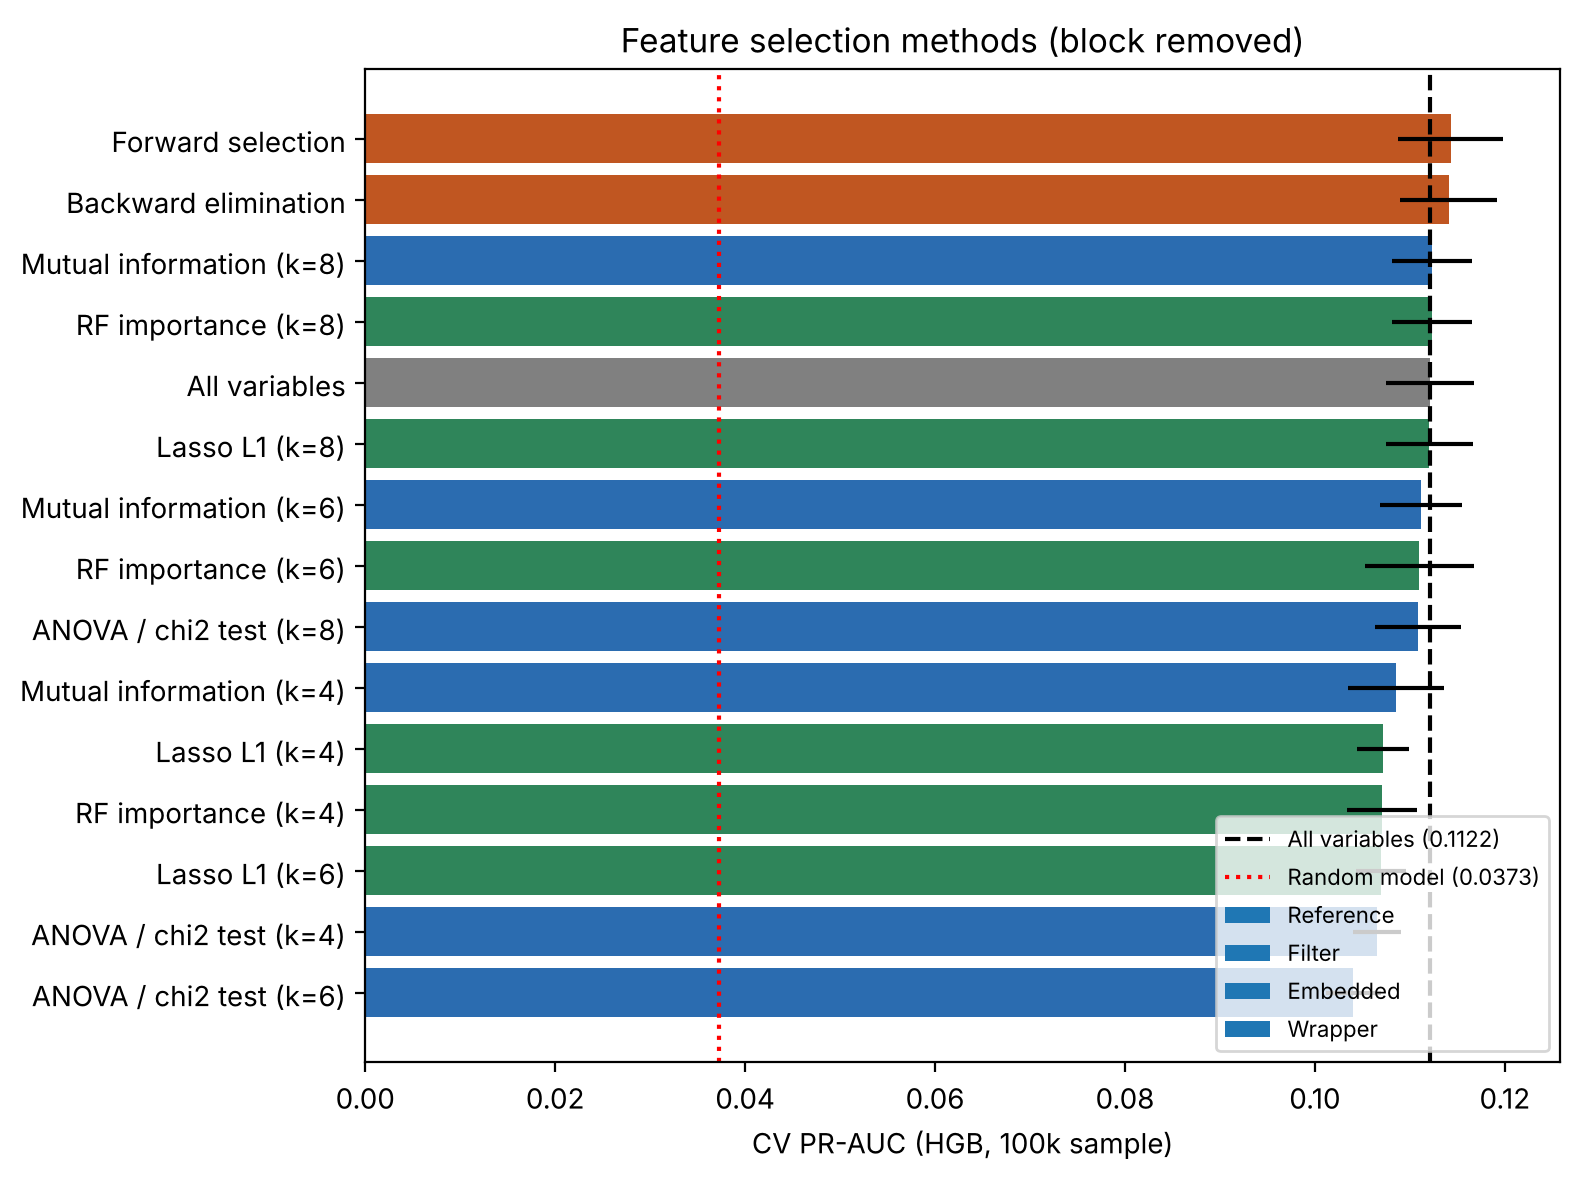

In [10]:
board = pd.DataFrame(results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
pd.set_option("display.width", 220, "display.max_colwidth", 90)
print(board.drop(columns="Variables").round(4).to_string())

colors = {"Reference": "grey", "Filter": "#2B6CB0", "Embedded": "#2F855A", "Wrapper": "#C05621"}
v = board.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(v["Method"], v["PR_AUC"], xerr=v["sd"], color=[colors[f] for f in v["Family"]])
ref = board.loc[board.Family == "Reference", "PR_AUC"].iloc[0]
ax.axvline(ref, color="black", ls="--", label=f"All variables ({ref:.4f})")
ax.axvline(ys.mean(), color="red", ls=":", label=f"Random model ({ys.mean():.4f})")
for fam, col in colors.items():
    ax.barh([], [], color=col, label=fam)
ax.set_xlabel("CV PR-AUC (HGB, 100k sample)")
ax.set_title("Feature selection methods (block removed)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 9. Which variables do we keep?
If the scores are very close, we keep the simplest model: among the methods that are within one standard deviation of the best score, we take the one with the fewest variables.

In [11]:
top = board.iloc[0]
limit = top["PR_AUC"] - top["sd"]
ok = board[board["PR_AUC"] >= limit].sort_values(["N_var", "PR_AUC"], ascending=[True, False])
chosen = ok.iloc[0]
chosen_vars = chosen["Variables"].split(", ")
print(f"Best score: {top['Method']} ({top['PR_AUC']:.4f} +/- {top['sd']:.4f}) -> limit {limit:.4f}")
print(f"Chosen: {chosen['Method']} with {len(chosen_vars)} variables: {chosen_vars}")
print(f"Removed variables: {[c for c in RAW if c not in chosen_vars]}")

Best score: Forward selection (0.1143 +/- 0.0055) -> limit 0.1088
Chosen: Forward selection with 4 variables: ['BonusMalus', 'Exposure', 'VehAge', 'DrivAge']
Removed variables: ['VehPower', 'Density', 'Area', 'VehBrand', 'VehGas', 'Region']


## 10. Check on the full train set, then test (only once)
We compare HGB with all variables and HGB with the chosen variables, using the same 5 folds as the main notebook on the full train set.
The F1 threshold is chosen on the out-of-fold predictions, then the test set is used once.

In [12]:
Xtr_cap, Xte_cap = cap_and_log(Xtr), cap_and_log(Xte)

def full_cv(cols):
    oof, s = np.zeros(len(ytr)), []
    for a, b in folds:
        m = make_hgb().fit(Xtr_cap.iloc[a][cols], ytr.iloc[a])
        oof[b] = m.predict_proba(Xtr_cap.iloc[b][cols])[:, 1]
        s.append(average_precision_score(ytr.iloc[b], oof[b]))
    prec, rec, thr = precision_recall_curve(ytr, oof)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return np.mean(s), np.std(s), thr[i]

final = {}
for name, cols in [("HGB all variables", RAW), (f"HGB {len(chosen_vars)} variables", chosen_vars)]:
    t = time.time()
    cv_mean, cv_sd, thr = full_cv(cols)
    m = make_hgb().fit(Xtr_cap[cols], ytr)
    p = m.predict_proba(Xte_cap[cols])[:, 1]
    final[name] = {"N_var": len(cols), "CV PR-AUC": cv_mean, "CV sd": cv_sd, "Test PR-AUC": average_precision_score(yte, p),
                   "Test lift": average_precision_score(yte, p) / yte.mean(), "Test ROC-AUC": roc_auc_score(yte, p),
                   "Threshold (CV)": thr, "Test F1": f1_score(yte, p >= thr),
                   "Test precision": precision_score(yte, p >= thr), "Test recall": recall_score(yte, p >= thr),
                   "time_s": time.time() - t}
print(pd.DataFrame(final).T.round(4).to_string())

                   N_var  CV PR-AUC   CV sd  Test PR-AUC  Test lift  Test ROC-AUC  Threshold (CV)  Test F1  Test precision  Test recall  time_s
HGB all variables   10.0     0.1182  0.0028       0.1187     3.1856        0.7112          0.0926   0.1829          0.1610       0.2118  37.823
HGB 4 variables      4.0     0.1170  0.0012       0.1160     3.1118        0.7033          0.1011   0.1834          0.1767       0.1906  22.895


## 11. Conclusion
- Only 4 variables carry almost all the signal: BonusMalus, Exposure, VehAge and DrivAge. The forward selection keeps only these 4, and all methods put BonusMalus and Exposure at the top.
- With these 4 variables, HGB gets almost the same score as with all 10: CV PR-AUC 0.1170 vs 0.1182, test PR-AUC 0.1160 vs 0.1187 (lift 3.1 vs 3.2). The difference is small (about one standard deviation).
- The 6 other variables (VehPower, Density, Area, VehBrand, VehGas, Region) add only a little. Area brings nothing because it is very close to Density.
- Wrappers (forward, backward) find the best small groups of variables but are the slowest (about 3 minutes each, vs 6-14 s). Filters and embedded methods are fast but need more variables (k=8) to reach the same score; with k=4 or 6 they lose more.
- Same F1 for both models on the test set (0.183), with a threshold of about 0.09-0.10 chosen with CV.
- Choice: for the final model we keep all 10 variables (best score). The 4-variable model is a good simpler option, easier to explain to an insurer.
- Limits: the methods were compared on a 100,000-row sample to save time. The wrappers choose and score the variables on the same folds, so their sample score is a bit optimistic; that is why we checked the result again on the full train set (section 10).